<a href="https://colab.research.google.com/github/drijal/BDMS_STI_2026/blob/main/notebooks/BDC_3a_GDP_Nowcasting_ML_Workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

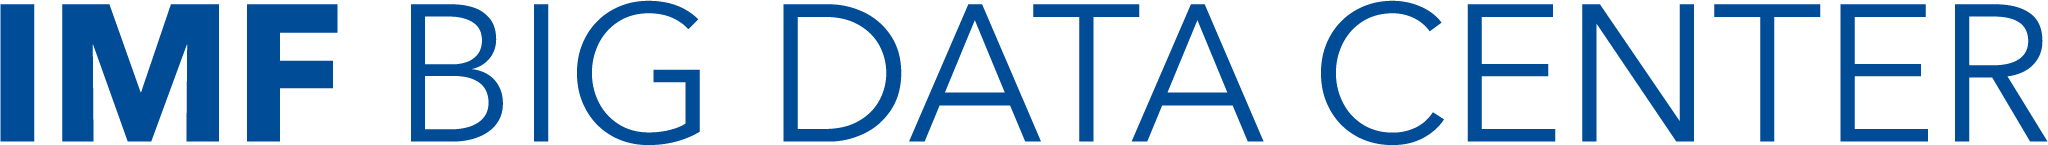


# Nowcasting GDP Using Satellite Data and Machine Learning

---

**Contributors:** [Iyke Maduako](imaduako@imf.org), [Alberto Sanchez](asanchez3@imf.org), [Alessandra Sozzi](asozzi@imf.org)
<br>**Last update:** 2026-10 (Created: 2025-May) — revised training version (see *Change log* at the end)
<br>**Description:** Train a model to nowcast quarterly GDP growth, check how accurate it would have been in real time, explain its predictions, and produce a nowcast for the latest quarters. Useful in the context of the IMF's NowHub framework.
<br>**References:**

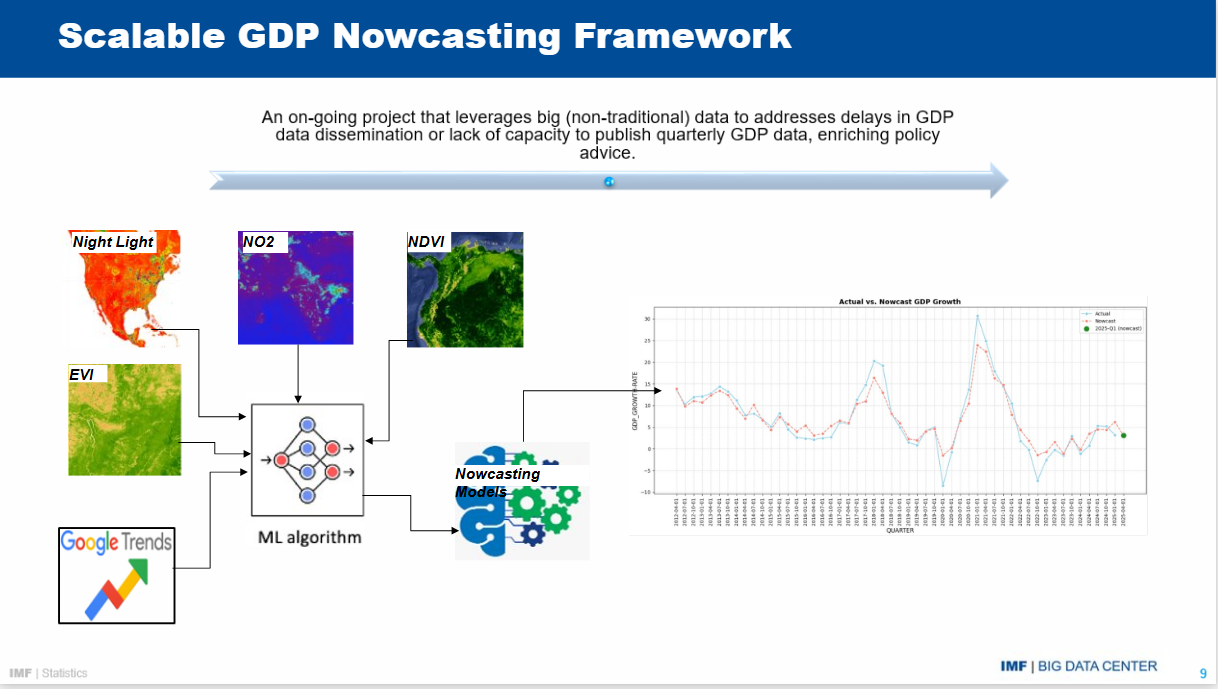

## Outline

GDP is published with a lag. **Nowcasting** means estimating GDP for a quarter that has already happened (or is happening) but has not yet been published, using faster indicators.

In this notebook we:

1. Load satellite and search indicators for Nigeria, plus GDP growth.
2. Train a **Random Forest** on past quarters.
3. Test it on the **most recent quarters it has never seen**, and compare it with a simple benchmark.
4. Look inside the model with **SHAP** to see which indicators drive each prediction.
5. Simulate **real-time nowcasting**: each quarter, retrain using only the data available up to that point.
6. Produce the final nowcast for quarters where GDP is not yet published.

## 1. Set-up

Mount Google Drive, install SHAP (used for explaining the model), and import the libraries we need.

⚠ **You may need to restart the session after the install.**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install shap

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import shap

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

## 2. Load the data

The dataset is ready-made: one row per quarter, with satellite/search indicators and GDP growth. All series are already **imputed and differenced**, so they fluctuate around a stable average rather than trending upwards — models handle this much better than raw levels (see `BDC_Data_Preprocessing_for_GDP_Nowcasting`).

The last rows have **no GDP yet**. These are the quarters we want to nowcast.

⏰ **Adjust the path to your Drive folder.**

In [ ]:

ROOT = "/content/drive/MyDrive/BDMS_STI_2026-main/"   # if using Colab
data_path = os.path.join(ROOT, "data")
input_path = os.path.join(data_path, "Model Data")

os.path.exists(input_path)

CountryName = "Mongolia"
CountryCode ="MNG"

df_imported = pd.read_csv(os.path.join(input_path, f"model_data_{CountryCode.lower()}.csv"))
df_imported.tail()

,quarter,diff_mean_ntl,diff_sum_ntl,diff_mean_no2,diff_sum_no2,diff_sum_evi,diff_mean_evi,diff_mean_ndvi,diff_sum_ndvi,diff_mean_pcp,...,diff_sum_vhi,diff_mean_vhi,diff_gti_tourism,diff_sum_ndvi_anomaly,diff_mean_ndvi_anomaly,diff_mean_asi,diff_sum_asi,n_months,date,GDP
58,2025Q3,130.883310,130.883310,11.111111,2.244663,-6.436937,-6.437025,-7.559758,-7.559487,-14.688042,...,-16.251893,-16.251893,345.050505,-1.037333,-0.019210,10.549170,530.382,3,2025-09-30,7.6
59,2025Q4,-13.516050,-13.516050,-33.333333,-29.624002,-11.679323,-11.623061,-14.434031,-14.489478,10.058915,...,-15.948175,-15.948175,635.622896,-1.711000,-0.032412,20.178750,80.715,3,2025-12-31,11.0
60,2026Q1,10.199569,10.199569,-33.333333,-47.212471,-7.983477,-7.981681,-10.580944,-10.582729,2.227909,...,5.383730,5.383730,451.111111,-1.051000,-0.020227,-8.751200,-87.512,3,2026-03-31,11.5
61,2026Q2,-40.935540,-40.935540,0.000000,-2.302670,-1.773247,-1.740483,-0.457903,-0.491049,9.078994,...,5.943883,5.943883,291.495726,0.356333,0.006599,8.165303,419.008,3,2026-06-30,9.6
62,2026Q3,-23.586391,-23.586391,-13.888889,-12.638478,1.788977,1.707977,3.124303,3.206348,-15.180046,...,30.562742,8.845863,-20.638441,7.824667,0.030412,-11.307971,-500.884,3,2026-09-30,NaN


In [ ]:
df_imported.head()

,quarter,diff_mean_ntl,diff_sum_ntl,diff_mean_no2,diff_sum_no2,diff_sum_evi,diff_mean_evi,diff_mean_ndvi,diff_sum_ndvi,diff_mean_pcp,...,diff_sum_vhi,diff_mean_vhi,diff_gti_tourism,diff_sum_ndvi_anomaly,diff_mean_ndvi_anomaly,diff_mean_asi,diff_sum_asi,n_months,date,GDP
0,2011Q1,0.000000,0.000000,-16.666667,9.828513,-10.320287,-10.315614,-6.425197,-6.430057,-26.065997,...,-4.052538,-4.052538,-3.571429,1.022000,0.018926,7.276400,72.764,3,2011-03-31,16.3
1,2011Q2,0.000000,0.000000,11.111111,11.024402,3.459263,3.500794,2.517969,2.476981,0.644704,...,1.984559,1.984559,0.462963,0.841000,0.015574,-2.182968,-123.858,3,2011-06-30,1.2
2,2011Q3,0.000000,0.000000,-9.259259,-7.130522,10.191673,10.180427,8.375345,8.386338,1.583247,...,12.635396,12.635396,11.904762,-0.617667,-0.011438,0.266393,0.321,3,2011-09-30,7.3
3,2011Q4,0.000000,0.000000,-8.333333,-1.592146,-1.846100,-1.796756,-2.996288,-3.045203,-9.926624,...,0.243047,0.243047,7.222222,-1.234333,-0.022858,2.797500,11.190,3,2011-12-31,15.5
4,2012Q1,11.133856,11.133856,-16.666667,2.467810,34.837351,34.820731,36.888126,36.904985,-28.727909,...,6.450898,6.450898,41.388889,0.670667,0.012420,-0.298000,-2.980,3,2012-03-31,4.6


▶ *You can use `BDC_Data_Extract_Satellite_Data` and `BDC_Data_Preprocessing_for_GDP_Nowcasting` to build the same file for another country (extraction may take long).*

## 3. Choose the indicators (features)

We keep the `sum` version of each satellite indicator, the Google Trends tourism series, and GDP growth (the **target**).

| Short name | Indicator |
|---|---|
| `ntl` | Night-time lights |
| `evi`, `ndvi` | Vegetation indices |
| `ndvi_anomaly` | Vegetation vs. normal for the season |
| `no2` | Nitrogen dioxide (pollution, linked to industry and traffic) |
| `pcp` | Precipitation |
| `asi`, `vhi` | Agricultural stress / vegetation health |
| `gti_tourism` | Google Trends: tourism searches |

We do **not** use the year as a feature: a Random Forest cannot extrapolate a time trend, and it would make the explanations harder to read.

<h3><b>❓ Would you keep both the Mean and Sum versions of each satellite indicator? Why, or why not?</b></h3>

In [ ]:
df = df_imported.drop(columns=["n_months","date"])

# shorter column names, and a proper date column
df.columns = df.columns.str.replace('diff_', '')
df = df.rename(columns={'quarter': 'date'})

df['date'] = pd.PeriodIndex(df['date'], freq='Q').to_timestamp(how='end').normalize()

# feature_cols = ['ntl', 'evi', 'ndvi', 'no2', 'pcp', 'asi', 'ndvi_anomaly', 'vhi', 'gti_tourism']
feature_cols = [
    'mean_ntl', 'sum_ntl',
    'mean_evi', 'sum_evi',
    'mean_ndvi', 'sum_ndvi',
    'mean_no2', 'sum_no2',
    'mean_pcp', 'sum_pcp',
    'mean_asi', 'sum_asi',
    'mean_ndvi_anomaly', 'sum_ndvi_anomaly',
    'mean_vhi', 'sum_vhi',
    'gti_tourism'
]

df.tail()

,date,mean_ntl,sum_ntl,mean_no2,sum_no2,sum_evi,mean_evi,mean_ndvi,sum_ndvi,mean_pcp,sum_pcp,sum_vhi,mean_vhi,gti_tourism,sum_ndvi_anomaly,mean_ndvi_anomaly,mean_asi,sum_asi,GDP
58,2025-09-30,130.883310,130.883310,11.111111,2.244663,-6.436937,-6.437025,-7.559758,-7.559487,-14.688042,-14.688042,-16.251893,-16.251893,345.050505,-1.037333,-0.019210,10.549170,530.382,7.6
59,2025-12-31,-13.516050,-13.516050,-33.333333,-29.624002,-11.679323,-11.623061,-14.434031,-14.489478,10.058915,10.058915,-15.948175,-15.948175,635.622896,-1.711000,-0.032412,20.178750,80.715,11.0
60,2026-03-31,10.199569,10.199569,-33.333333,-47.212471,-7.983477,-7.981681,-10.580944,-10.582729,2.227909,2.227909,5.383730,5.383730,451.111111,-1.051000,-0.020227,-8.751200,-87.512,11.5
61,2026-06-30,-40.935540,-40.935540,0.000000,-2.302670,-1.773247,-1.740483,-0.457903,-0.491049,9.078994,9.078994,5.943883,5.943883,291.495726,0.356333,0.006599,8.165303,419.008,9.6
62,2026-09-30,-23.586391,-23.586391,-13.888889,-12.638478,1.788977,1.707977,3.124303,3.206348,-15.180046,-15.180046,30.562742,8.845863,-20.638441,7.824667,0.030412,-11.307971,-500.884,NaN


In [ ]:
df.tail()

,date,mean_ntl,sum_ntl,mean_no2,sum_no2,sum_evi,mean_evi,mean_ndvi,sum_ndvi,mean_pcp,sum_pcp,sum_vhi,mean_vhi,gti_tourism,sum_ndvi_anomaly,mean_ndvi_anomaly,mean_asi,sum_asi,GDP
58,2025-09-30,130.883310,130.883310,11.111111,2.244663,-6.436937,-6.437025,-7.559758,-7.559487,-14.688042,-14.688042,-16.251893,-16.251893,345.050505,-1.037333,-0.019210,10.549170,530.382,7.6
59,2025-12-31,-13.516050,-13.516050,-33.333333,-29.624002,-11.679323,-11.623061,-14.434031,-14.489478,10.058915,10.058915,-15.948175,-15.948175,635.622896,-1.711000,-0.032412,20.178750,80.715,11.0
60,2026-03-31,10.199569,10.199569,-33.333333,-47.212471,-7.983477,-7.981681,-10.580944,-10.582729,2.227909,2.227909,5.383730,5.383730,451.111111,-1.051000,-0.020227,-8.751200,-87.512,11.5
61,2026-06-30,-40.935540,-40.935540,0.000000,-2.302670,-1.773247,-1.740483,-0.457903,-0.491049,9.078994,9.078994,5.943883,5.943883,291.495726,0.356333,0.006599,8.165303,419.008,9.6
62,2026-09-30,-23.586391,-23.586391,-13.888889,-12.638478,1.788977,1.707977,3.124303,3.206348,-15.180046,-15.180046,30.562742,8.845863,-20.638441,7.824667,0.030412,-11.307971,-500.884,NaN


Split the data into quarters where GDP is **known** (used to train and test) and quarters where GDP is **missing** (to be nowcast).

In [ ]:
known = df.dropna(subset=['GDP']).reset_index(drop=True)
to_nowcast = df[df['GDP'].isna()].reset_index(drop=True)

print("Quarters with known GDP:", len(known))
print("Quarters to nowcast:", list(to_nowcast['date'].dt.date))

Quarters with known GDP: 62
Quarters to nowcast: [datetime.date(2026, 9, 30)]


## 4. Explore: do the indicators move with GDP?

A quick first check before modelling. Correlation is only a screen: a weakly correlated indicator can still help in combination with others, and a strong correlation does not imply causation.

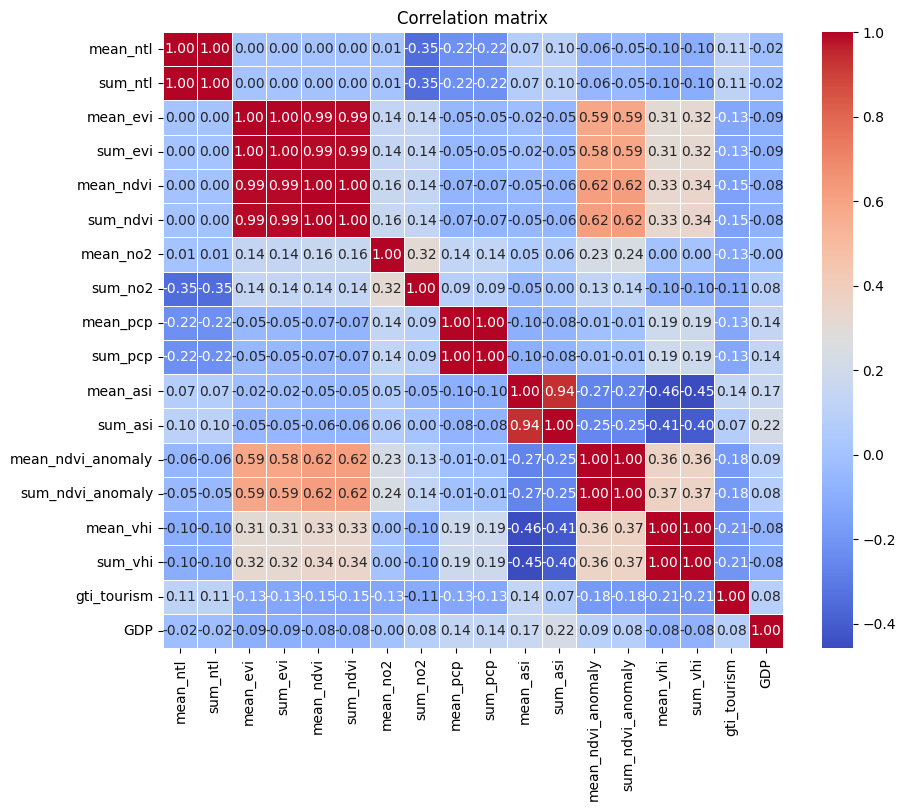

In [ ]:
corr = known[feature_cols + ['GDP']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation matrix')
plt.show()

In [ ]:
# Try different indicators
indic1 = 'mean_ntl'
indic2 = 'mean_evi'

fig = go.Figure()
fig.add_trace(go.Scatter(x=known['date'], y=known[indic1], name=indic1))
fig.add_trace(go.Scatter(x=known['date'], y=known[indic2], name=indic2))
fig.add_trace(go.Scatter(x=known['date'], y=known['GDP'], name='GDP', yaxis='y2'))
fig.update_layout(title=f"{indic1} and {indic2} vs. GDP growth, {CountryName}",
                  yaxis_title='Indicator (differenced)',
                  yaxis2=dict(title='GDP growth (%)', overlaying='y', side='right'))
fig.show()

## 5. Train and test the model

### 5.1 Split by time

With time series we **never shuffle**. We train on older quarters and hold out the **last 4 known quarters** as a test set — just as a real nowcaster only has the past. The test set tells us how the model would have performed on quarters it has never seen.

*Note: 4 quarters is a small test set, so treat the error numbers as indicative, not definitive.*

In [ ]:
n_test = 4

train = known.iloc[:-n_test]
test = known.iloc[-n_test:]

X_train, y_train = train[feature_cols], train['GDP']
X_test, y_test = test[feature_cols], test['GDP']

print("Train:", train['date'].min().date(), "to", train['date'].max().date(), f"({len(train)} quarters)")
print("Test: ", test['date'].min().date(), "to", test['date'].max().date(), f"({len(test)} quarters)")

Train: 2011-03-31 to 2025-06-30 (58 quarters)
Test:  2025-09-30 to 2026-06-30 (4 quarters)


### 5.2 Train a Random Forest

A **Random Forest** averages many simple decision trees. Each tree asks a series of yes/no questions (e.g. *"did night lights grow by more than X?"*) and ends with a GDP estimate; the forest averages them. This captures non-linear patterns and is fairly robust, but it **cannot predict values outside the range seen in training**.

☝ Visual intro: http://www.r2d3.us/visual-intro-to-machine-learning-part-1/

In [ ]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

pred_rf = model.predict(X_test)

### 5.3 Is it any good? Compare with a benchmark

An error number on its own means little. We compare the model with a simple **benchmark**: always predict the average GDP growth of the training period. If the model cannot beat this, it is not adding value.

- **MAE** (mean absolute error): typical size of the error, in percentage points of GDP growth.
- **RMSE** (root mean squared error): similar, but penalises large misses more.

In [ ]:
pred_bench = np.full(len(y_test), y_train.mean())

results = pd.DataFrame({
    'MAE':  [mean_absolute_error(y_test, pred_rf), mean_absolute_error(y_test, pred_bench)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, pred_rf)), np.sqrt(mean_squared_error(y_test, pred_bench))]},
    index=['Random Forest', 'Benchmark (historical mean)'])
display(results.round(3))

display(pd.DataFrame({'date': test['date'].dt.date, 'Actual': y_test,
                      'Random Forest': pred_rf, 'Benchmark': pred_bench}).round(3))

,MAE,RMSE
Random Forest,1.509,1.961
Benchmark (historical mean),2.198,2.565


,date,Actual,Random Forest,Benchmark
58,2025-09-30,7.6,7.895,7.853
59,2025-12-31,11.0,10.175,7.853
60,2026-03-31,11.5,10.162,7.853
61,2026-06-30,9.6,6.020,7.853


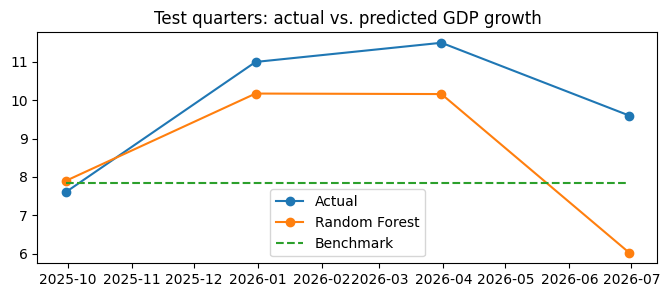

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(test['date'], y_test, marker='o', label='Actual')
plt.plot(test['date'], pred_rf, marker='o', label='Random Forest')
plt.plot(test['date'], pred_bench, linestyle='--', label='Benchmark')
plt.title('Test quarters: actual vs. predicted GDP growth')
plt.legend()
plt.show()

<h3><b>❓ Does the model beat the benchmark? By enough to matter?</b></h3>

## 6. Explain the model with SHAP

SHAP breaks each prediction into contributions from each indicator. It starts from the model's **average prediction** (the base value) and shows how much each indicator pushed the prediction up (red) or down (blue).

Remember: SHAP explains **the model**, not the economy. It shows what the model relies on, not causal effects. Here it is computed on only 4 test quarters, so read it as illustrative.

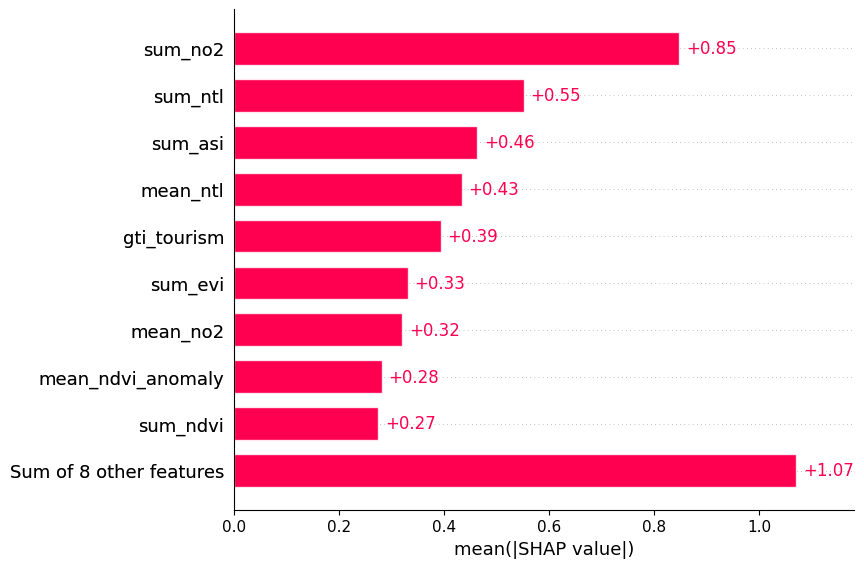

In [ ]:
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_test)

# Overall importance: average size of each indicator's contribution
shap.plots.bar(shap_values)

Quarter: 2026-06-30


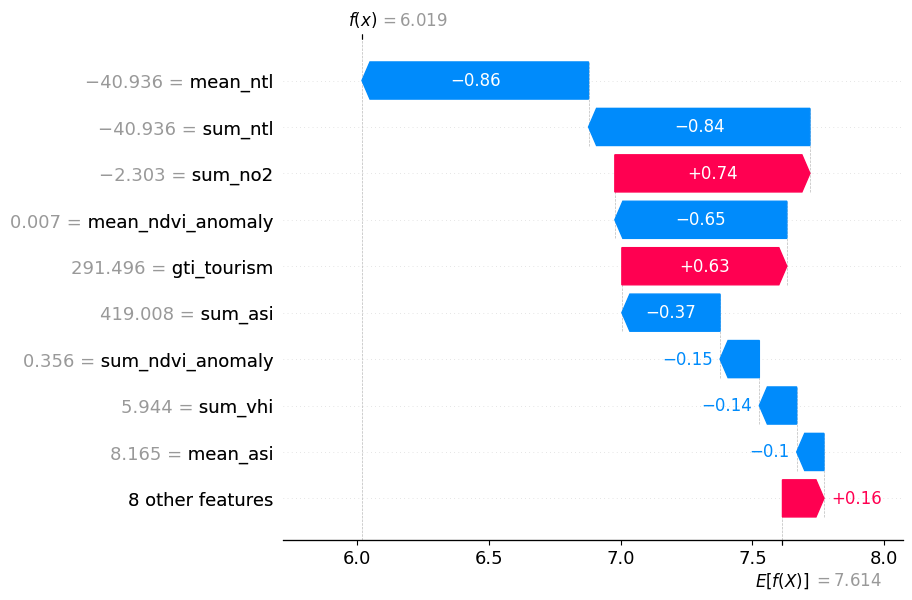

In [ ]:
# One quarter in detail: how the model built its prediction for the first test quarter
print("Quarter:", test['date'].iloc[3].date())
shap.plots.waterfall(shap_values[3])

**Reading the waterfall:** start at the base value E[f(x)] (the model's average prediction), add each indicator's contribution, and you arrive at f(x), the model's prediction for that quarter.

## 7. Simulate real-time nowcasting

In practice, each time a new quarter of GDP is published we add it to the data, retrain, and nowcast the next quarter. Below we replay this for the 4 test quarters.

For each quarter, the model is trained **only on quarters before it** (an *expanding window*: the training set grows by one quarter each step). This is the most honest estimate of real-time accuracy.

**Expanding window** is ideal for Quarterly Data (avoids losing scarce observations) and ML models that are data hungry like RF, XGBoost, KNN.

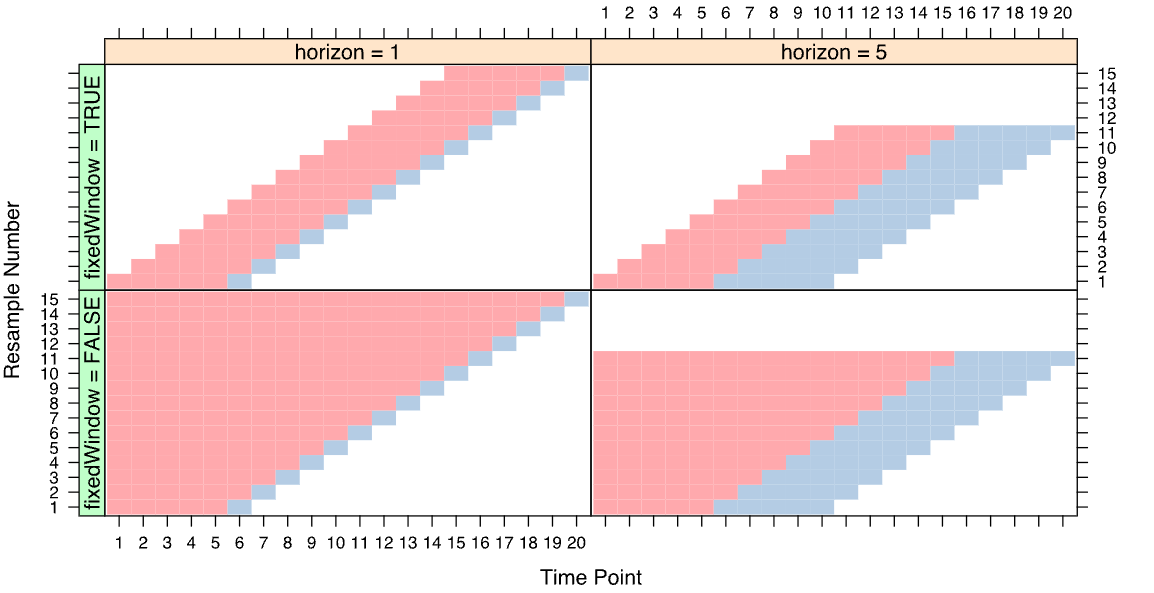

Image Source: https://topepo.github.io/caret/data-splitting.html#data-splitting-for-time-series

In [ ]:
realtime_preds = []

for i in range(len(known) - n_test, len(known)):
    past = known.iloc[:i]                      # only quarters before quarter i
    current = known.iloc[[i]]                  # the quarter we nowcast

    rt_model = RandomForestRegressor(n_estimators=100, random_state=42)
    rt_model.fit(past[feature_cols], past['GDP'])
    nowcast = rt_model.predict(current[feature_cols])[0]
    realtime_preds.append(nowcast)

    print(f"{current['date'].iloc[0].date()} | trained on {len(past)} quarters | "
          f"nowcast {nowcast:.3f} | actual {current['GDP'].iloc[0]:.3f}")

print("\nReal-time RMSE:", round(np.sqrt(mean_squared_error(y_test, realtime_preds)), 3))

2025-09-30 | trained on 58 quarters | nowcast 7.895 | actual 7.600
2025-12-31 | trained on 59 quarters | nowcast 10.482 | actual 11.000
2026-03-31 | trained on 60 quarters | nowcast 10.169 | actual 11.500
2026-06-30 | trained on 61 quarters | nowcast 5.395 | actual 9.600

Real-time RMSE: 2.225


<h3><b>❓ Is real-time retraining more accurate than training once (section 5)? Why might it be?</b></h3>

## 8. Produce the final nowcast (train on 100% of the data)

Now we use **all quarters with known GDP** to train the final model, and nowcast the quarters where GDP is not yet published.

We assume all indicators are already available for those quarters. In real nowcasting, data release lags matter and some indicators may be missing for the latest quarter.

In [ ]:
known

,date,mean_ntl,sum_ntl,mean_no2,sum_no2,sum_evi,mean_evi,mean_ndvi,sum_ndvi,mean_pcp,sum_pcp,sum_vhi,mean_vhi,gti_tourism,sum_ndvi_anomaly,mean_ndvi_anomaly,mean_asi,sum_asi,GDP
0,2011-03-31,0.000000,0.000000,-16.666667,9.828513,-10.320287,-10.315614,-6.425197,-6.430057,-26.065997,-26.065997,-4.052538,-4.052538,-3.571429,1.022000,0.018926,7.276400,72.764,16.3
1,2011-06-30,0.000000,0.000000,11.111111,11.024402,3.459263,3.500794,2.517969,2.476981,0.644704,0.644704,1.984559,1.984559,0.462963,0.841000,0.015574,-2.182968,-123.858,1.2
2,2011-09-30,0.000000,0.000000,-9.259259,-7.130522,10.191673,10.180427,8.375345,8.386338,1.583247,1.583247,12.635396,12.635396,11.904762,-0.617667,-0.011438,0.266393,0.321,7.3
3,2011-12-31,0.000000,0.000000,-8.333333,-1.592146,-1.846100,-1.796756,-2.996288,-3.045203,-9.926624,-9.926624,0.243047,0.243047,7.222222,-1.234333,-0.022858,2.797500,11.190,15.5
4,2012-03-31,11.133856,11.133856,-16.666667,2.467810,34.837351,34.820731,36.888126,36.904985,-28.727909,-28.727909,6.450898,6.450898,41.388889,0.670667,0.012420,-0.298000,-2.980,4.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,2025-06-30,122.412977,122.412977,0.000000,4.910578,-3.560402,-3.583371,-3.666091,-3.643014,-18.425553,-18.425553,-7.225243,-7.225243,18.333333,-0.762667,-0.018981,3.035524,163.051,5.6
58,2025-09-30,130.883310,130.883310,11.111111,2.244663,-6.436937,-6.437025,-7.559758,-7.559487,-14.688042,-14.688042,-16.251893,-16.251893,345.050505,-1.037333,-0.019210,10.549170,530.382,7.6
59,2025-12-31,-13.516050,-13.516050,-33.333333,-29.624002,-11.679323,-11.623061,-14.434031,-14.489478,10.058915,10.058915,-15.948175,-15.948175,635.622896,-1.711000,-0.032412,20.178750,80.715,11.0
60,2026-03-31,10.199569,10.199569,-33.333333,-47.212471,-7.983477,-7.981681,-10.580944,-10.582729,2.227909,2.227909,5.383730,5.383730,451.111111,-1.051000,-0.020227,-8.751200,-87.512,11.5


In [ ]:
model_final = RandomForestRegressor(n_estimators=100, random_state=42)
model_final.fit(known[feature_cols], known['GDP'])

to_nowcast['nowcast'] = model_final.predict(to_nowcast[feature_cols])
display(to_nowcast[['date', 'nowcast']].round(3))

,date,nowcast
0,2026-09-30,9.629


The plot shows actual GDP, the **real-time nowcasts** from section 7 (honest, out-of-sample), and the **final nowcasts** for unpublished quarters.

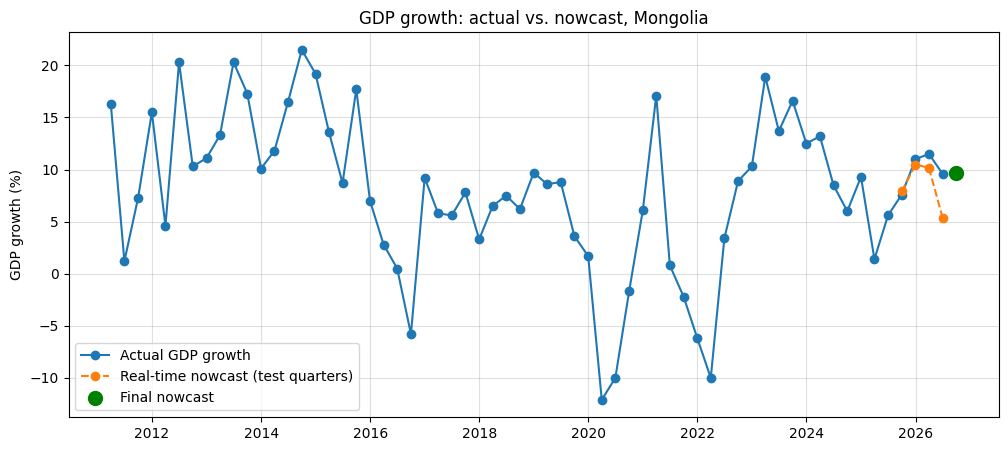

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(known['date'], known['GDP'], marker='o', label='Actual GDP growth')
plt.plot(test['date'], realtime_preds, marker='o', linestyle='--', label='Real-time nowcast (test quarters)')
plt.scatter(to_nowcast['date'], to_nowcast['nowcast'], color='green', s=100, zorder=5, label='Final nowcast')
plt.title(f'GDP growth: actual vs. nowcast, {CountryName}')
plt.ylabel('GDP growth (%)')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

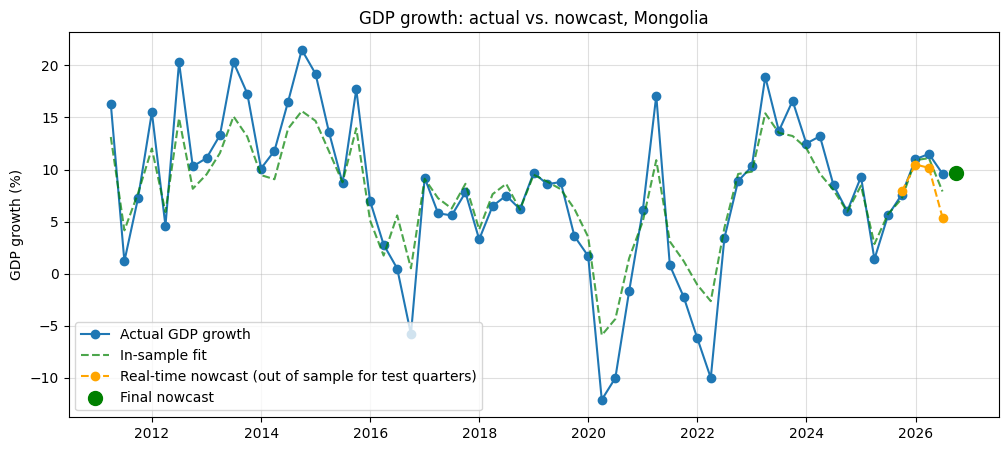

In [27]:
known['nowcast_all'] = model_final.predict(known[feature_cols])
to_nowcast['nowcast_all'] = model_final.predict(to_nowcast[feature_cols])

plt.figure(figsize=(12, 5))

# Actual GDP
plt.plot(
    known['date'], known['GDP'],
    marker='o',
    label='Actual GDP growth'
)

# In-sample fitted predictions across all historical quarters
plt.plot(
    known['date'], known['nowcast_all'],
    linestyle='--',
    color='green',
    alpha=0.7,
    label='In-sample fit'
)

# Real-time predictions for test quarters
plt.plot(
    test['date'], realtime_preds,
    marker='o',
    linestyle='--',
    color='orange',
    label='Real-time nowcast (out of sample for test quarters)'
)

# Final prediction for unseen quarter
plt.scatter(
    to_nowcast['date'], to_nowcast['nowcast'],
    color='green',
    s=100,
    zorder=5,
    label='Final nowcast'
)

plt.title(f'GDP growth: actual vs. nowcast, {CountryName}')
plt.ylabel('GDP growth (%)')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

⚠️Diagnostic only: The historical fitted line above is generated using a model trained on those same observations. It illustrates model fit and should not be interpreted as out-of-sample nowcasting performance. Use the held-out and real-time results above to assess predictive accuracy.


## 9. Save the nowcast and the model

We save the actual GDP, the real-time nowcasts for the test quarters, and the final nowcasts, together with the model that produced the final nowcasts.

In [ ]:
known['realtime_nowcast'] = np.nan
known.loc[known.index[-n_test:], 'realtime_nowcast'] = realtime_preds

output = pd.concat([known[['date', 'GDP', 'realtime_nowcast']],
                    to_nowcast[['date', 'nowcast']]], ignore_index=True)
output.to_csv(os.path.join(data_path, 'mng_pred_data.csv'), index=False)
display(output.tail(8))

with open(os.path.join(data_path, 'model_mng.pkl'), 'wb') as f:
    pickle.dump(model_final, f)

,date,GDP,realtime_nowcast,nowcast
55,2024-12-31,9.3,NaN,NaN
56,2025-03-31,1.4,NaN,NaN
57,2025-06-30,5.6,NaN,NaN
58,2025-09-30,7.6,7.895,NaN
59,2025-12-31,11.0,10.482,NaN
60,2026-03-31,11.5,10.169,NaN
61,2026-06-30,9.6,5.395,NaN
62,2026-09-30,NaN,NaN,9.629


## 10. Optional: tuning the model

So far we used default Random Forest settings (*hyperparameters*), such as the number of trees and how deep each tree can grow. **Tuning** tries different settings and keeps the best.

To respect time order:
- the search uses **only the training quarters**;
- inside them, `TimeSeriesSplit` always validates on quarters that come *after* the ones used for fitting;
- the winning settings are then checked on the same **4 held-out test quarters** as in section 5.

`RandomizedSearchCV` tries a random sample of setting combinations (here 20). `GridSearchCV` would try every combination: more thorough, but much slower, and with little data rarely better.

⚠ May take a minute or two to run.

In [ ]:
param_options = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [1.0, 'sqrt', 0.5]
}

search = RandomizedSearchCV(RandomForestRegressor(random_state=42),
                            param_distributions=param_options, n_iter=20,
                            cv=TimeSeriesSplit(n_splits=5),
                            scoring='neg_mean_squared_error',
                            random_state=42, n_jobs=-1)
search.fit(X_train, y_train)
print("Best settings:", search.best_params_)

pred_tuned = search.best_estimator_.predict(X_test)

results.loc['Tuned Random Forest'] = [mean_absolute_error(y_test, pred_tuned),
                                      np.sqrt(mean_squared_error(y_test, pred_tuned))]
display(results.round(3))

Best settings: {'n_estimators': 200, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 10}


,MAE,RMSE
Random Forest,1.509,1.961
Benchmark (historical mean),2.198,2.565
Tuned Random Forest,2.724,3.004


<h3><b>❓ Did tuning beat the default model on the held-out quarters, and is the gap large enough to matter?</b></h3>

*Other models:* scikit-learn offers many alternatives that can be swapped in for the Random Forest in the same workflow: https://scikit-learn.org/stable/api/sklearn.ensemble.html